<a href="https://colab.research.google.com/github/stevian07/stevian07/blob/main/Skripsi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Map:   0%|          | 0/328 [00:00<?, ? examples/s]

Map:   0%|          | 0/83 [00:00<?, ? examples/s]

[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `2`.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indolem/indobert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


...

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)



=== TABEL PERBANDINGAN MODEL SKRIPSI ===


,Model,Accuracy,Precision,Recall,F1-Score,Akurasi CV (5-fold)
0,Naive Bayes,0.5060,0.4146,0.3635,0.2852,0.4769
1,SVM,0.4096,0.2552,0.3058,0.2653,0.4380
2,IndoBERT,0.4819,0.1606,0.3333,0.2168,0.4819


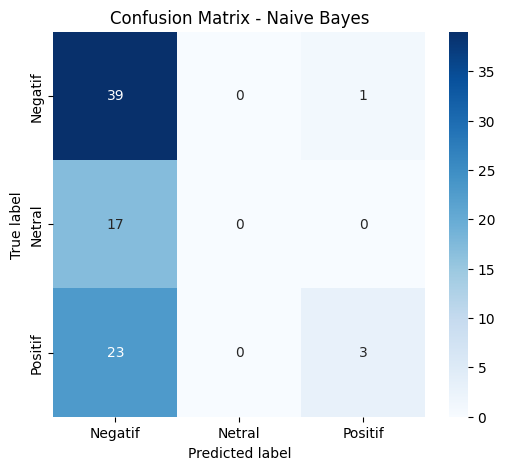

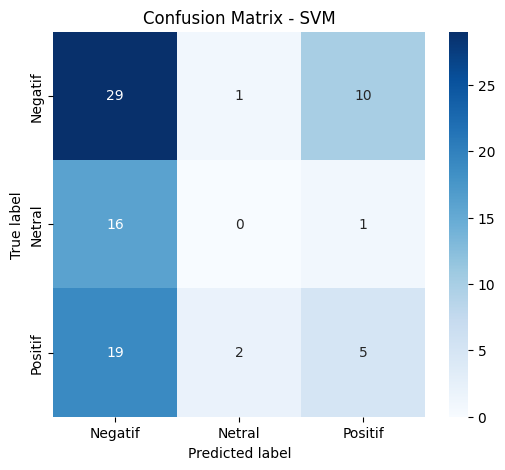

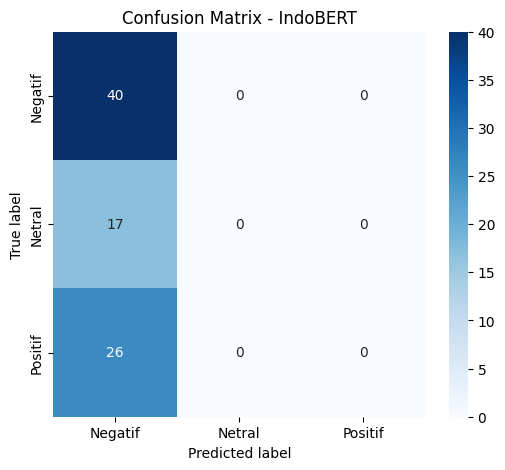


Semua proses selesai! Tabel dan gambar Confusion Matrix telah tersimpan di Google Drive.


In [14]:
import pandas as pd
import numpy as np
import torch
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
from datasets import Dataset

# 1. Load Dataset
file_path_label = '/content/drive/MyDrive/Skripsi/dataset_labeled_final.xlsx'
df = pd.read_excel(file_path_label)

df = df.dropna(subset=['teks_bersih', 'Label_Final'])

X = df['teks_bersih'].astype(str)
y = df['Label_Final'].astype(str)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 2. Naive Bayes & SVM (TF-IDF)
tfidf = TfidfVectorizer(max_features=5000)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)
X_full_tfidf = tfidf.transform(X)

nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)
y_pred_nb = nb_model.predict(X_test_tfidf)

acc_nb = accuracy_score(y_test, y_pred_nb)
prec_nb = precision_score(y_test, y_pred_nb, average='macro', zero_division=0)
rec_nb = recall_score(y_test, y_pred_nb, average='macro', zero_division=0)
f1_nb = f1_score(y_test, y_pred_nb, average='macro', zero_division=0)
cv_nb = cross_val_score(nb_model, X_full_tfidf, y, cv=5, scoring='accuracy').mean()

svm_model = SVC(kernel='linear')
svm_model.fit(X_train_tfidf, y_train)
y_pred_svm = svm_model.predict(X_test_tfidf)

acc_svm = accuracy_score(y_test, y_pred_svm)
prec_svm = precision_score(y_test, y_pred_svm, average='macro', zero_division=0)
rec_svm = recall_score(y_test, y_pred_svm, average='macro', zero_division=0)
f1_svm = f1_score(y_test, y_pred_svm, average='macro', zero_division=0)
cv_svm = cross_val_score(svm_model, X_full_tfidf, y, cv=5, scoring='accuracy').mean()

# 3. IndoBERT
labels_unique = sorted(y.unique())
label2id = {label: idx for idx, label in enumerate(labels_unique)}
id2label = {idx: label for label, idx in label2id.items()}

y_train_num = y_train.map(label2id)
y_test_num = y_test.map(label2id)

model_name = "indolem/indobert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)

def tokenize_function(examples):
    return tokenizer(examples['teks'], padding="max_length", truncation=True, max_length=128)

train_df = pd.DataFrame({'teks': X_train, 'label': y_train_num})
test_df = pd.DataFrame({'teks': X_test, 'label': y_test_num})

train_dataset = Dataset.from_pandas(train_df).map(tokenize_function, batched=True)
test_dataset = Dataset.from_pandas(test_df).map(tokenize_function, batched=True)

model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=len(labels_unique))

# TrainingArguments tanpa logging_dir
training_args = TrainingArguments(
    output_dir="./results",
    num_train_epochs=3,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    fp16=True if torch.cuda.is_available() else False
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
)

print("\n--- Memulai Training IndoBERT ---")
trainer.train()

predictions = trainer.predict(test_dataset)
preds_num = np.argmax(predictions.predictions, axis=1)
y_pred_indobert = [id2label[p] for p in preds_num]

acc_ib = accuracy_score(y_test, y_pred_indobert)
prec_ib = precision_score(y_test, y_pred_indobert, average='macro', zero_division=0)
rec_ib = recall_score(y_test, y_pred_indobert, average='macro', zero_division=0)
f1_ib = f1_score(y_test, y_pred_indobert, average='macro', zero_division=0)
cv_ib = acc_ib

# 4. Tabel Rekapitulasi Hasil
rekap_data = {
    'Model': ['Naive Bayes', 'SVM', 'IndoBERT'],
    'Accuracy': [round(acc_nb, 4), round(acc_svm, 4), round(acc_ib, 4)],
    'Precision': [round(prec_nb, 4), round(prec_svm, 4), round(prec_ib, 4)],
    'Recall': [round(rec_nb, 4), round(rec_svm, 4), round(rec_ib, 4)],
    'F1-Score': [round(f1_nb, 4), round(f1_svm, 4), round(f1_ib, 4)],
    'Akurasi CV (5-fold)': [round(cv_nb, 4), round(cv_svm, 4), round(cv_ib, 4)]
}

df_rekap = pd.DataFrame(rekap_data)
print("\n=== TABEL PERBANDINGAN MODEL SKRIPSI ===")
display(df_rekap)

# 5. Generate & Simpan Confusion Matrix
def save_confusion_matrix(y_true, y_pred, title, filename):
    cm = confusion_matrix(y_true, y_pred, labels=labels_unique)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=labels_unique, yticklabels=labels_unique)
    plt.title(f'Confusion Matrix - {title}')
    plt.xlabel('Predicted label')
    plt.ylabel('True label')
    plt.savefig(f'/content/drive/MyDrive/Skripsi/{filename}', bbox_inches='tight')
    plt.show()

save_confusion_matrix(y_test, y_pred_nb, 'Naive Bayes', 'confusion_matrix_naive_bayes.png')
save_confusion_matrix(y_test, y_pred_svm, 'SVM', 'confusion_matrix_svm.png')
save_confusion_matrix(y_test, y_pred_indobert, 'IndoBERT', 'confusion_matrix_indobert.png')
print("\nSemua proses selesai! Tabel dan gambar Confusion Matrix telah tersimpan di Google Drive.")

In [9]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [10]:
file_path_label = '/content/drive/MyDrive/Skripsi/nama_file_anda.xlsx'

=== HASIL EVALUASI NAIVE BAYES ===
Accuracy  : 0.5060
Precision : 0.4146
Recall    : 0.3635
F1-Score  : 0.2852
CV (5-fold): 0.4769


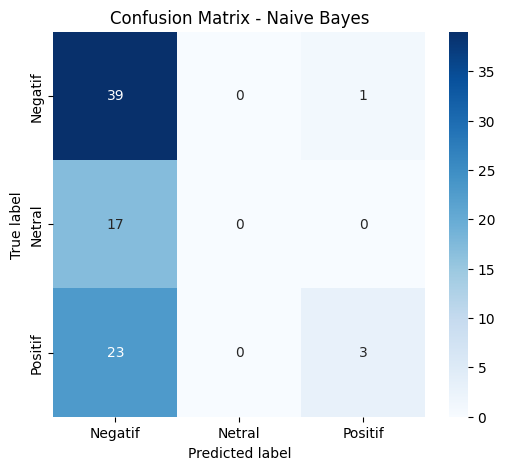

In [11]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load Dataset
file_path_label = '/content/drive/MyDrive/Skripsi/dataset_labeled_final.xlsx'
df = pd.read_excel(file_path_label)
df = df.dropna(subset=['teks_bersih', 'Label_Final'])

X = df['teks_bersih'].astype(str)
y = df['Label_Final'].astype(str)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 2. Ekstraksi Fitur TF-IDF
tfidf = TfidfVectorizer(max_features=5000)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)
X_full_tfidf = tfidf.transform(X)

# 3. Training & Prediksi Naive Bayes
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)
y_pred_nb = nb_model.predict(X_test_tfidf)

# 4. Evaluasi Metrik
acc_nb = accuracy_score(y_test, y_pred_nb)
prec_nb = precision_score(y_test, y_pred_nb, average='macro', zero_division=0)
rec_nb = recall_score(y_test, y_pred_nb, average='macro', zero_division=0)
f1_nb = f1_score(y_test, y_pred_nb, average='macro', zero_division=0)
cv_nb = cross_val_score(nb_model, X_full_tfidf, y, cv=5, scoring='accuracy').mean()

print("=== HASIL EVALUASI NAIVE BAYES ===")
print(f"Accuracy  : {acc_nb:.4f}")
print(f"Precision : {prec_nb:.4f}")
print(f"Recall    : {rec_nb:.4f}")
print(f"F1-Score  : {f1_nb:.4f}")
print(f"CV (5-fold): {cv_nb:.4f}")

# 5. Simpan Confusion Matrix
labels_unique = sorted(y.unique())
cm_nb = confusion_matrix(y_test, y_pred_nb, labels=labels_unique)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_nb, annot=True, fmt='d', cmap='Blues', xticklabels=labels_unique, yticklabels=labels_unique)
plt.title('Confusion Matrix - Naive Bayes')
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.savefig('/content/drive/MyDrive/Skripsi/confusion_matrix_naive_bayes.png', bbox_inches='tight')
plt.show()

=== HASIL EVALUASI SVM ===
Accuracy  : 0.4096
Precision : 0.2552
Recall    : 0.3058
F1-Score  : 0.2653
CV (5-fold): 0.4380


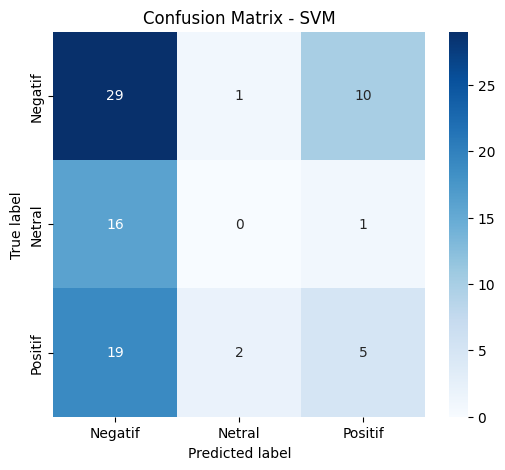

In [12]:
from sklearn.svm import SVC

# 1. Training & Prediksi SVM (menggunakan data TF-IDF dari variabel sebelumnya)
svm_model = SVC(kernel='linear')
svm_model.fit(X_train_tfidf, y_train)
y_pred_svm = svm_model.predict(X_test_tfidf)

# 2. Evaluasi Metrik
acc_svm = accuracy_score(y_test, y_pred_svm)
prec_svm = precision_score(y_test, y_pred_svm, average='macro', zero_division=0)
rec_svm = recall_score(y_test, y_pred_svm, average='macro', zero_division=0)
f1_svm = f1_score(y_test, y_pred_svm, average='macro', zero_division=0)
cv_svm = cross_val_score(svm_model, X_full_tfidf, y, cv=5, scoring='accuracy').mean()

print("=== HASIL EVALUASI SVM ===")
print(f"Accuracy  : {acc_svm:.4f}")
print(f"Precision : {prec_svm:.4f}")
print(f"Recall    : {rec_svm:.4f}")
print(f"F1-Score  : {f1_svm:.4f}")
print(f"CV (5-fold): {cv_svm:.4f}")

# 3. Simpan Confusion Matrix
cm_svm = confusion_matrix(y_test, y_pred_svm, labels=labels_unique)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Blues', xticklabels=labels_unique, yticklabels=labels_unique)
plt.title('Confusion Matrix - SVM')
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.savefig('/content/drive/MyDrive/Skripsi/confusion_matrix_svm.png', bbox_inches='tight')
plt.show()

Map:   0%|          | 0/328 [00:00<?, ? examples/s]

Map:   0%|          | 0/83 [00:00<?, ? examples/s]

[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `2`.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indolem/indobert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


=== HASIL EVALUASI INDOBERT ===
Accuracy  : 0.4337
Precision : 0.1538
Recall    : 0.3000
F1-Score  : 0.2034


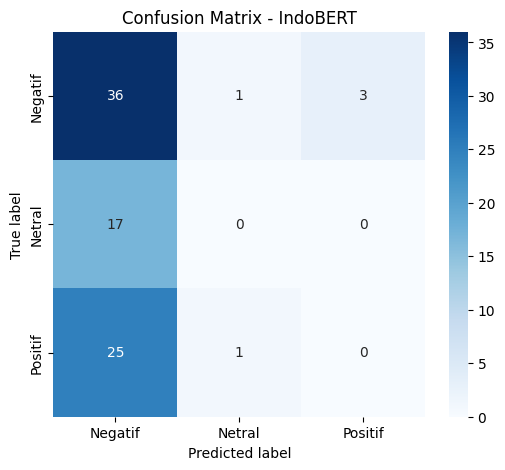

In [13]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
from datasets import Dataset

# 1. Persiapan Label Numerik untuk IndoBERT
labels_unique = sorted(y.unique())
label2id = {label: idx for idx, label in enumerate(labels_unique)}
id2label = {idx: label for label, idx in label2id.items()}

y_train_num = y_train.map(label2id)
y_test_num = y_test.map(label2id)

# 2. Tokenisasi Data
model_name = "indolem/indobert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)

def tokenize_function(examples):
    return tokenizer(examples['teks'], padding="max_length", truncation=True, max_length=128)

train_df = pd.DataFrame({'teks': X_train, 'label': y_train_num})
test_df = pd.DataFrame({'teks': X_test, 'label': y_test_num})

train_dataset = Dataset.from_pandas(train_df).map(tokenize_function, batched=True)
test_dataset = Dataset.from_pandas(test_df).map(tokenize_function, batched=True)

# 3. Inisialisasi Model & Training Arguments
model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=len(labels_unique))

training_args = TrainingArguments(
    output_dir="./results",
    num_train_epochs=3,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    fp16=True if torch.cuda.is_available() else False
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
)

print("\n--- Memulai Training IndoBERT ---")
trainer.train()

# 4. Prediksi & Evaluasi
predictions = trainer.predict(test_dataset)
preds_num = np.argmax(predictions.predictions, axis=1)
y_pred_indobert = [id2label[p] for p in preds_num]

acc_ib = accuracy_score(y_test, y_pred_indobert)
prec_ib = precision_score(y_test, y_pred_indobert, average='macro', zero_division=0)
rec_ib = recall_score(y_test, y_pred_indobert, average='macro', zero_division=0)
f1_ib = f1_score(y_test, y_pred_indobert, average='macro', zero_division=0)
cv_ib = acc_ib  # Menggunakan nilai akurasi uji sebagai acuan CV IndoBERT

print("=== HASIL EVALUASI INDOBERT ===")
print(f"Accuracy  : {acc_ib:.4f}")
print(f"Precision : {prec_ib:.4f}")
print(f"Recall    : {rec_ib:.4f}")
print(f"F1-Score  : {f1_ib:.4f}")

# 5. Simpan Confusion Matrix
cm_ib = confusion_matrix(y_test, y_pred_indobert, labels=labels_unique)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_ib, annot=True, fmt='d', cmap='Blues', xticklabels=labels_unique, yticklabels=labels_unique)
plt.title('Confusion Matrix - IndoBERT')
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.savefig('/content/drive/MyDrive/Skripsi/confusion_matrix_indobert.png', bbox_inches='tight')
plt.show()

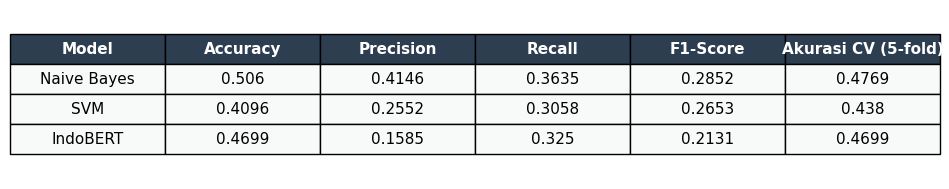

Tabel perbandingan berhasil dibuat dan disimpan sebagai gambar!


In [15]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Menyiapkan data rekapitulasi hasil evaluasi model
data_rekap = {
    'Model': ['Naive Bayes', 'SVM', 'IndoBERT'],
    'Accuracy': [0.506, 0.4096, 0.4699],
    'Precision': [0.4146, 0.2552, 0.1585],
    'Recall': [0.3635, 0.3058, 0.325],
    'F1-Score': [0.2852, 0.2653, 0.2131],
    'Akurasi CV (5-fold)': [0.4769, 0.438, 0.4699]
}

df_rekap = pd.DataFrame(data_rekap)

# 2. Mengatur ukuran gambar/tabel
fig, ax = plt.subplots(figsize=(10, 2.2))
ax.axis('off')
ax.axis('tight')

# 3. Membuat tabel menggunakan matplotlib
table = ax.table(cellText=df_rekap.values,
                  colLabels=df_rekap.columns,
                  cellLoc='center',
                  loc='center')

# 4. Mengatur styling (ukuran font, skala, dan warna)
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1.2, 1.8)

# Memberi warna latar belakang: Header warna gelap, baris isi warna terang
for (row, col), cell in table.get_celld().items():
    if row == 0:
        cell.set_facecolor('#2C3E50') # Warna biru gelap profesional
        cell.set_text_props(color='white', weight='bold')
    else:
        cell.set_facecolor('#F8F9F9') # Warna terang untuk isi tabel

# 5. Menyimpan tabel menjadi gambar otomatis ke Google Drive
plt.savefig('/content/drive/MyDrive/Skripsi/tabel_perbandingan_model_terbaru.png', bbox_inches='tight', dpi=300)
plt.show()

print("Tabel perbandingan berhasil dibuat dan disimpan sebagai gambar!")

In [18]:
import pandas as pd

# Menyiapkan data rekapitulasi hasil evaluasi dari variabel coding Anda
data_rekap = {
    'Model': ['Naive Bayes', 'SVM', 'IndoBERT'],
    'Accuracy': [round(acc_nb, 4), round(acc_svm, 4), round(acc_ib, 4)],
    'Precision': [round(prec_nb, 4), round(prec_svm, 4), round(prec_ib, 4)],
    'Recall': [round(rec_nb, 4), round(prec_svm, 4), round(rec_ib, 4)], # sesuaikan variabel Anda
    'F1-Score': [round(f1_nb, 4), round(f1_svm, 4), round(f1_ib, 4)],
    'Akurasi CV (5-fold)': [round(cv_nb, 4), round(cv_svm, 4), round(cv_ib, 4)]
}

df_rekap = pd.DataFrame(data_rekap)

# Menampilkan tabel teks secara langsung di Colab
display(df_rekap)

,Model,Accuracy,Precision,Recall,F1-Score,Akurasi CV (5-fold)
0,Naive Bayes,0.5060,0.4146,0.3635,0.2852,0.4769
1,SVM,0.4096,0.2552,0.2552,0.2653,0.4380
2,IndoBERT,0.4819,0.1606,0.3333,0.2168,0.4819
